In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [16]:
df = pd.read_csv("/Users/omikapatel/Desktop/Python_Decal/course_assignments/homework9/noisy_curvefit_data.csv")
print(df.shape) # 100 rows 6 columns
print(df.head())
print(df.tail())

for col in df.columns:
    print(col)

(100, 6)
          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850
x
y_noise_1
y_noise_2
y_noise_3
y_noise_4
y_noise_5


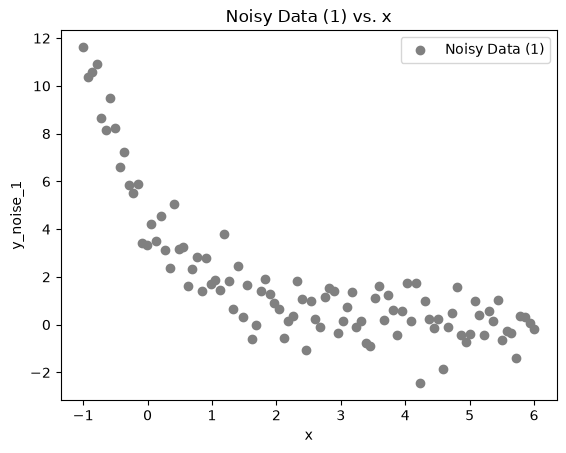

In [19]:
plt.scatter(df['x'], df['y_noise_1'], color='gray', label='Noisy Data (1)')

plt.xlabel('x')
plt.ylabel('y_noise_1')
plt.title('Noisy Data (1) vs. x')
plt.legend()

plt.show()

Fit: y = 4.71 * e^(-0.92 * x)


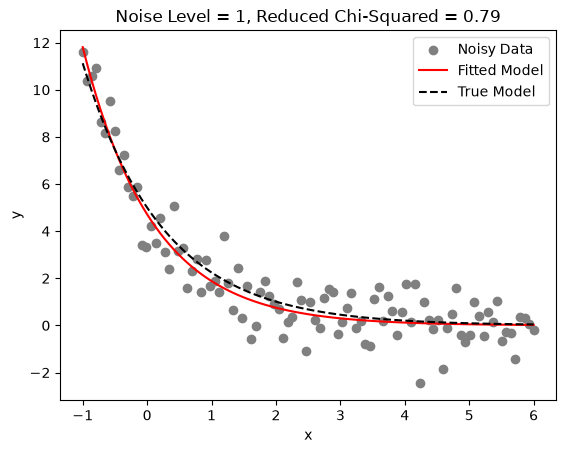

In [18]:
x = df['x']
y_noise_1 = df['y_noise_1']

def model(x, A, k):
    return A * np.exp(-k * x)

p0 = [1, 1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)

A_fit, k_fit = popt

print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof

plt.scatter(x, y_noise_1, color='gray', label='Noisy Data')
plt.plot(x, model(x, A_fit, k_fit), color='red', label='Fitted Model')
plt.plot(x, model(x, 5, 0.8), color='black', linestyle='--', label='True Model')

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Noise Level = 1, Reduced Chi-Squared = {chi2_reduced:.2f}')
plt.legend()
plt.show()

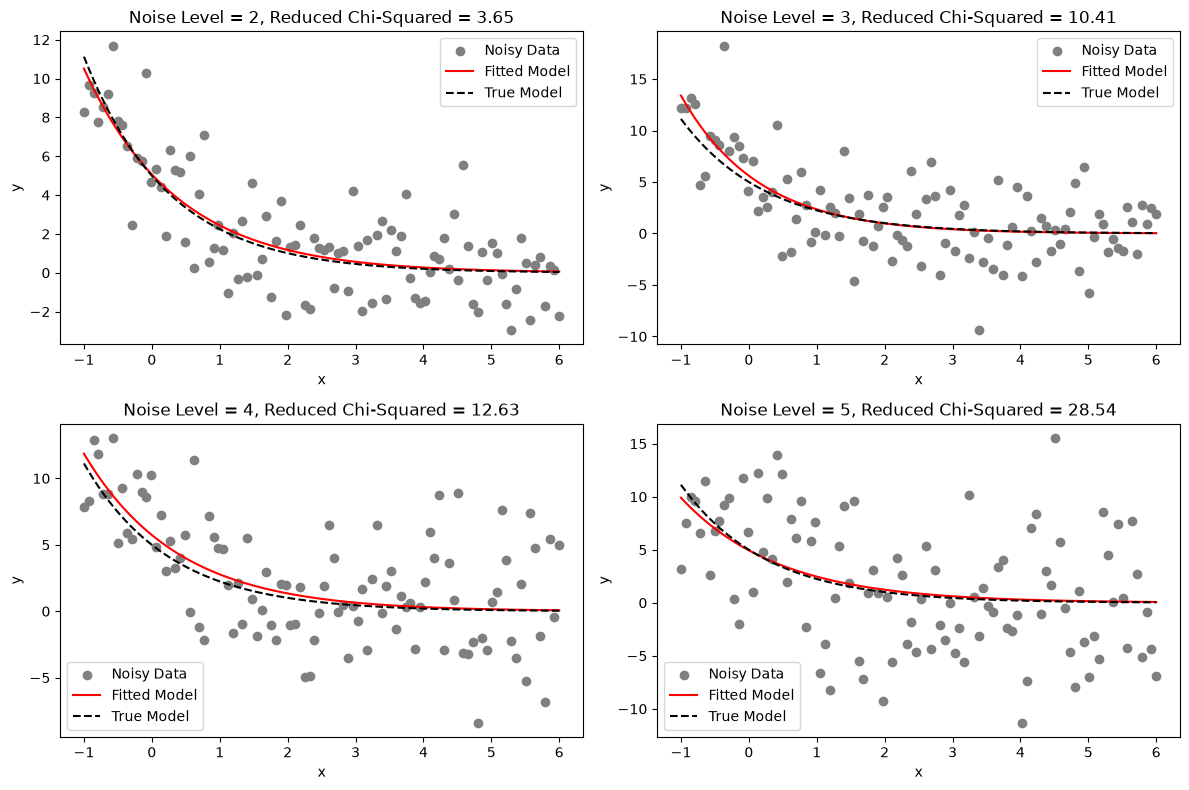

In [22]:
def fit_model(x, y):
    p0 = [1, 1]
    popt, pcov = curve_fit(model, x, y, p0=p0)
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return A_fit, k_fit, chi2_reduced

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
noise_levels = [2, 3, 4, 5]

for i, noise in enumerate(noise_levels):
    y = df[f'y_noise_{noise}']

    A_fit, k_fit, chi2_reduced = fit_model(x, y)

    axes[i].scatter(x, y, color='gray', label='Noisy Data')

    axes[i].plot(x, model(x, A_fit, k_fit),
                 color='red', label='Fitted Model')

    axes[i].plot(x, model(x, 5, 0.8),
                 color='black', linestyle='--', label='True Model')

    axes[i].set_title(f'Noise Level = {noise}, Reduced Chi-Squared = {chi2_reduced:.2f}')
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('y')
    axes[i].legend()

plt.tight_layout()
plt.show()

In [ ]:
#1. The red line generally moves further away from the black line because more noise makes the model harder to fit accurately; black line stays same
#2. The reduced chi-squared increases because the data points are more spread out from the fitted line; larger residuals

In [24]:
import pandas as pd

results = []

for noise in [1, 2, 3, 4, 5]:
    y = df[f'y_noise_{noise}']
    A_fit, k_fit, chi2_reduced = fit_model(x, y)

    results.append([noise, A_fit, k_fit, chi2_reduced])

results_df = pd.DataFrame(results, columns=[
    'Noise Level', 'A_fit', 'k_fit', 'Reduced Chi-Squared'
])

results_df.to_csv("noisy_parameters.csv", index=False)
results_df

,Noise Level,A_fit,k_fit,Reduced Chi-Squared
0,1,4.714814,0.918308,0.790673
1,2,5.063889,0.730396,3.649382
2,3,5.609396,0.870372,10.410207
3,4,5.738727,0.725965,12.626832
4,5,4.943458,0.695012,28.538124
